# DM-2 : Boosting et cartes de saillance

---

In [ ]:
# Code snippet for loading MNIST data and preprocessing using PCA
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier


In [18]:
seed = 42

## Chargement des données

In [ ]:
# Load MNIST data
X_mnist, y_mnist = fetch_openml('mnist_784', return_X_y=True, as_frame=False)

## Question 1 - les différents modèles

#### Les fonctions utiles

In [14]:
resultats = []

def evaluer(nom, y_true, y_pred):
    """Calcule les métriques d'un modèle"""
    ligne = {
        "Modèle": nom,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Précision macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Rappel macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_true, y_pred, average="macro"),
    }
    # si on réévalue un modèle déjà présent, on remplace sa ligne au lieu de la dupliquer
    resultats[:] = [r for r in resultats if r["Modèle"] != nom]
    resultats.append(ligne)

    tableau = pd.DataFrame(resultats).set_index("Modèle").round(3)
    return tableau

#### Division des données

In [ ]:
# Split the data into training and test sets
split_size = int(X_mnist.shape[0] * 6/7)
X_train, y_train = X_mnist[:split_size]/255., y_mnist[:split_size]
X_test, y_test = X_mnist[split_size:]/255., y_mnist[split_size:]

#### Le hasard - DummyClassifier

In [22]:
X_bidon_train = np.zeros((len(y_train), 1))
X_bidon_test = np.zeros((len(y_test), 1))

dummy_strat = DummyClassifier(strategy="stratified", random_state=seed)
dummy_strat.fit(X_bidon_train, y_train)
evaluer("Dummy (hasard)", y_test, dummy_strat.predict(X_bidon_test))

,Accuracy,Précision macro,Rappel macro,F1 macro
Modèle,,,,
Dummy (hasard),0.1,0.1,0.1,0.1


#### Le modèle de base

In [23]:
model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=100,
    learning_rate=1.0
)

# Entraînement du modèle
model.fit(X_train, y_train)

# Prédiction sur l'ensemble de test
y_pred = model.predict(X_test)
evaluer("AdaBoost-base",y_test, y_pred)

,Accuracy,Précision macro,Rappel macro,F1 macro
Modèle,,,,
Dummy (hasard),0.100,0.100,0.100,0.1
AdaBoost-base,0.703,0.709,0.699,0.7


In [ ]:

# Calcul de la précision
print(f"Précision : {accuracy_score(y_test, y_pred):.4f}")
print("\nRapport de classification :")
print(classification_report(y_test, y_pred))

Précision : 0.5756

Rapport de classification :
              precision    recall  f1-score   support

           0       0.90      0.60      0.72       980
           1       0.90      0.32      0.48      1135
           2       0.56      0.67      0.61      1032
           3       0.44      0.65      0.53      1010
           4       0.50      0.51      0.50       982
           5       0.46      0.50      0.48       892
           6       0.82      0.70      0.76       958
           7       0.69      0.60      0.64      1028
           8       0.52      0.75      0.62       974
           9       0.43      0.47      0.45      1009

    accuracy                           0.58     10000
   macro avg       0.62      0.58      0.58     10000
weighted avg       0.63      0.58      0.58     10000



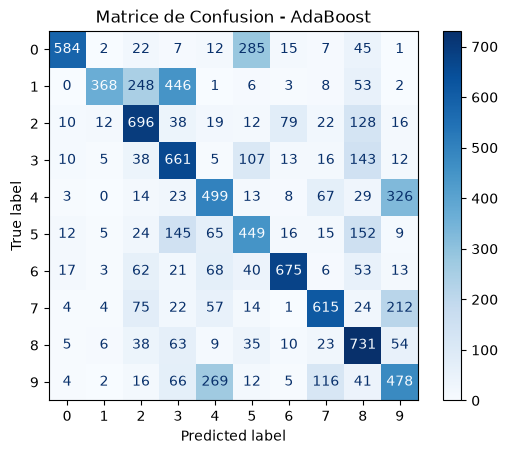

In [13]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot(cmap=plt.cm.Blues)
plt.title("Matrice de Confusion - AdaBoost")
plt.show()

#### Les différents paramètre à prendre en compte

L’idée est de tester l’algorithme AdaBoost sur les données MNIST (chiffres manuscrits décrits par 28 * 28, soit 784, pixels en niveaux de gris) en faisant varier :
- les classifieurs faibles : décision stumps, mais aussi perceptron et arbres de décision de profondeurs différentes
- le nombre d’étapes de boosting
- les classes binaires étudiées (e.g. les ‘3’ contre les ’8’, ou la classe de tous les chiffres entre ‘0’ et ‘4’ contre tous les chiffres entre ‘5’ et ‘9’)

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import Perceptron

weak_learners = {
    "Stump (profondeur 1)": DecisionTreeClassifier(max_depth=1),
    "Arbre (profondeur 3)": DecisionTreeClassifier(max_depth=3),
    "Arbre (profondeur 6)": DecisionTreeClassifier(max_depth=6),
    "Perceptron":           Perceptron(),
}

T = 200  # nombre maximal d'étapes de boosting

plt.figure(figsize=(8, 5))
for name, weak in weak_learners.items():
    clf = AdaBoostClassifier(estimator=weak, n_estimators=T,
                             algorithm="SAMME", random_state=0)
    clf.fit(X_train, y_train)

    # erreur de test après chaque étape de boosting
    test_err = [1 - np.mean(pred == y_test) for pred in clf.staged_predict(X_test)]
    plt.plot(range(1, T + 1), test_err, label=name)

plt.xlabel("Nombre d'étapes de boosting")
plt.ylabel("Erreur de test")
plt.legend()
plt.show()

TypeError: AdaBoostClassifier.__init__() got an unexpected keyword argument 'algorithm'

<Figure size 800x500 with 0 Axes>